In [6]:
import pandas as pd
import numpy as np

# Load the Week 10 dataset
df = pd.read_excel(r"C:\Users\Mpunga\Documents\week10_students.xlsx")

# Display the first five rows
print(df.head())

# Display dataset size
print("Dataset shape:", df.shape)

  student_id                name gender               program  district  \
0    AUCA001         Aline Uwase      F   Information Systems    Gasabo   
1    AUCA002     Eric Iradukunda      M  Software Engineering   Musanze   
2    AUCA003   Diane Uwizeyimana      F            Networking   Muhanga   
3    AUCA004  Jean Bosco Ikirezi      M            Accounting  Kicukiro   
4    AUCA005    Patrick Ingabire      M   Information Systems      Huye   

   attendance_pct  quiz_avg  assignments_avg  score  
0              55      31.0             35.0   28.6  
1              73      61.1             76.7   64.5  
2              92      35.2             65.5   52.7  
3              69      65.2             54.2   68.3  
4              88      39.3             42.9   42.3  
Dataset shape: (150, 9)


In [7]:
# Exercise 1.1 — Know your data
print("Dataset shape:", df.shape)
features = ["quiz_avg", "assignments_avg", "attendance_pct"]
correlations = df[features + ["score"]].corr()["score"].drop("score").sort_values(ascending=False)
print("\nCorrelation of each feature with score:")
print(correlations)


Dataset shape: (150, 9)

Correlation of each feature with score:
quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
Name: score, dtype: float64


In [8]:
# Exercise 1.2 — Frame & split
X = df[features]
y = df["score"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 112
Testing rows: 38


In [9]:
#  EXERCISE 2 

In [10]:
# Exercise 2.1 — Train & read the model
regression_model = LinearRegression()
regression_model.fit(X_train, y_train)

for feature, coefficient in zip(features, regression_model.coef_):
    print(f"{feature}: {coefficient:.4f}")
print("Intercept:", round(regression_model.intercept_, 4))


quiz_avg: 0.5790
assignments_avg: 0.3648
attendance_pct: 0.1134
Intercept: -4.4282


In [11]:
# Exercise 2.2 :TO Judge it honestly
test_predictions = regression_model.predict(X_test)
mae = mean_absolute_error(y_test, test_predictions)
r2 = r2_score(y_test, test_predictions)

print(f"MAE: {mae:.3f}")
print(f"R²: {r2:.3f}")



MAE: 3.329
R²: 0.887


In [12]:
# Exercise 2.3 :Predict a new student
new_student = pd.DataFrame(
    [[70, 75, 90]], columns=features
)
new_prediction = regression_model.predict(new_student)[0]
print(f"Predicted score for quiz=70, assignments=75, attendance=90: {new_prediction:.2f}")

#Prediction used invented personal values 
my_example = pd.DataFrame([[80, 85, 95]], columns=features)
my_prediction = regression_model.predict(my_example)[0]
print(f"Example prediction for invented values (80, 85, 95): {my_prediction:.2f}")


Predicted score for quiz=70, assignments=75, attendance=90: 73.66
Example prediction for invented values (80, 85, 95): 83.67


In [13]:
#EXERCICE 3

In [14]:
# Exercise 3.1 Build the target 
df["passed"] = (df["score"] >= 50).astype(int)
print("Pass/fail counts (1=pass, 0=fail):")
print(df["passed"].value_counts().sort_index().rename(index={0: "Fail", 1: "Pass"}))

X_class = df[features]
y_class = df["passed"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class, y_class, test_size=0.25, random_state=42
)

classifier = LogisticRegression(max_iter=1000)
classifier.fit(Xc_train, yc_train)
class_predictions = classifier.predict(Xc_test)


Pass/fail counts (1=pass, 0=fail):
passed
Fail     19
Pass    131
Name: count, dtype: int64


In [15]:
# Exercise 3.2  accuracy trap
model_accuracy = accuracy_score(yc_test, class_predictions)
baseline_accuracy = yc_test.mean()
cm = confusion_matrix(yc_test, class_predictions)

print(f"Model accuracy: {model_accuracy:.4f}")
print(f"Lazy baseline accuracy (predict pass for everyone): {baseline_accuracy:.4f}")
print("Confusion matrix (rows=actual [fail, pass], columns=predicted [fail, pass]):")
print(cm)


Model accuracy: 0.8947
Lazy baseline accuracy (predict pass for everyone): 0.8947
Confusion matrix (rows=actual [fail, pass], columns=predicted [fail, pass]):
[[ 3  1]
 [ 3 31]]


In [16]:
#EXERCISE 3 

In [17]:
# Exercise 4.1   more information help

X_quiz = df[["quiz_avg"]]
Xq_train, Xq_test, yq_train, yq_test = train_test_split(
    X_quiz, df["score"], test_size=0.25, random_state=42
)
quiz_model = LinearRegression().fit(Xq_train, yq_train)
quiz_r2 = r2_score(yq_test, quiz_model.predict(Xq_test))

# Version 2: all three numeric features
X_all = df[features]
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, df["score"], test_size=0.25, random_state=42
)
all_model = LinearRegression().fit(Xa_train, ya_train)
all_r2 = r2_score(ya_test, all_model.predict(Xa_test))

# Version 3: three numeric features + one-hot encoded program
X_program = pd.get_dummies(df[features + ["program"]], columns=["program"], dtype=int)
Xp_train, Xp_test, yp_train, yp_test = train_test_split(
    X_program, df["score"], test_size=0.25, random_state=42
)
program_model = LinearRegression().fit(Xp_train, yp_train)
program_r2 = r2_score(yp_test, program_model.predict(Xp_test))

print(f"Quiz only:                 {quiz_r2:.3f}")
print(f"All three numeric:         {all_r2:.3f}")
print(f"Numeric + program dummies: {program_r2:.3f}")

# The three numeric features improve R² substantially over quiz alone.
# Adding program does not improve the score here; it slightly lowers R².
# More features are not automatically better: they must add useful information.


Quiz only:                 0.624
All three numeric:         0.887
Numeric + program dummies: 0.880


In [18]:
#EXERCISE 5

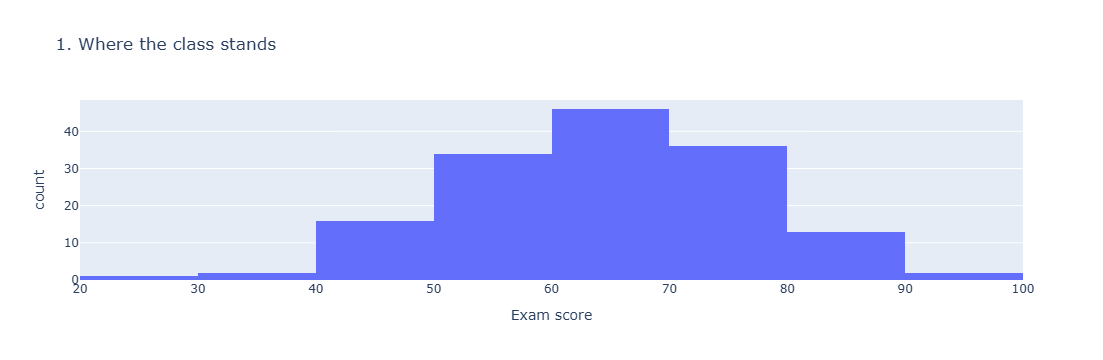

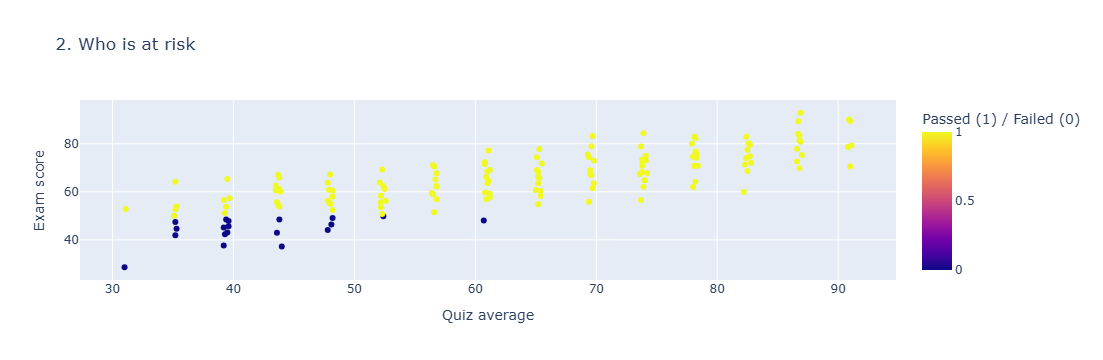

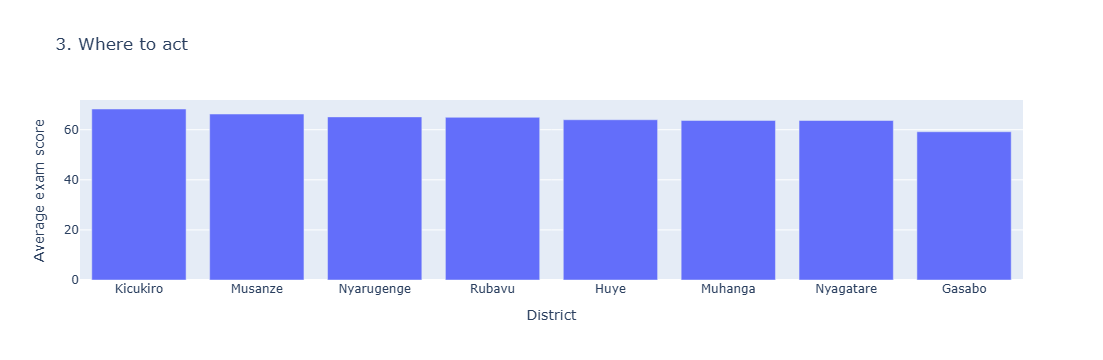

In [20]:
# Exercise 5.1 — The story in three charts
df["pass_status"] = df["passed"].map({0: "At risk / fail", 1: "Pass"})

fig1 = px.histogram(
    df, x="score", nbins=12,
    title="1. Where the class stands",
    labels={"score": "Exam score"}
)

fig2 = px.scatter(
    df, x="quiz_avg", y="score", color="passed",
    hover_name="name",
    title="2. Who is at risk",
    labels={"quiz_avg": "Quiz average", "score": "Exam score", "passed": "Passed (1) / Failed (0)"}
)

district_means = df.groupby("district", as_index=False)["score"].mean().sort_values("score", ascending=False)
fig3 = px.bar(
    district_means, x="district", y="score",
    title="3. Where to act",
    labels={"district": "District", "score": "Average exam score"}
)

fig1.show()
fig2.show()
fig3.show()


In [21]:
# Exercise 5.2 — GOING  TO PUBLISH IT 
import plotly.io as pio

dashboard_html = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>AUCA Class Dashboard</title>
<style>
body {{ font-family: Arial, sans-serif; margin: 0; padding: 24px; background: #f5f7fa; color: #172033; }}
main {{ max-width: 1100px; margin: auto; }}
h1 {{ margin-bottom: 4px; }}
p {{ color: #526078; }}
.chart {{ background: white; padding: 12px; margin: 18px 0; border-radius: 10px; }}
</style>
</head>
<body><main>
<h1>AUCA Student Performance Dashboard</h1>
<p>Week 10 Lab · Interactive charts. Hover over chart elements for details.</p>
<div class="chart">{pio.to_html(fig1, full_html=False, include_plotlyjs="cdn")}</div>
<div class="chart">{pio.to_html(fig2, full_html=False, include_plotlyjs=False)}</div>
<div class="chart">{pio.to_html(fig3, full_html=False, include_plotlyjs=False)}</div>
</main></body></html>"""

with open("class_dashboard.html", "w", encoding="utf-8") as f:
    f.write(dashboard_html)

print("Saved class_dashboard.html. Open it in a web browser and hover over the charts.")


Saved class_dashboard.html. Open it in a web browser and hover over the charts.
